Imports

In [112]:
from pathlib import Path
from Bio import SeqIO
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
import re

Domains

In [ ]:
input_dir = Path("../data/domains_positive")
fasta_files = list(input_dir.glob("*.fasta"))

output_file = input_dir / "all_DPO_candidates.fasta"

with open(output_file, "w") as outfile:
    for file in fasta_files:
        with open(file, "r") as infile:
            outfile.write(infile.read())

print(f"{len(fasta_files)} files combined into {output_file}")

8 files combined all_DPO_candidates.fasta


remove hypothetical proteins

In [62]:
input_fasta = Path("../data/domains_positive/all_DPO_candidates.fasta")
output_fasta = Path("../data/domains_positive/all_DPO_positive.fasta")

kept = []
removed = 0

for record in SeqIO.parse(input_fasta, "fasta"):
    header = record.description.lower()
    if "hypothetical" not in header:
        kept.append(record)
    else:
        removed += 1

SeqIO.write(kept, output_fasta, "fasta")

print(f"Kept: {len(kept)}")
print(f"Removed: {removed}")

Kept: 1764
Removed: 277


In [10]:
positive = Path("../data/domains_positive/all_DPO_positive.fasta")
negative = Path("../data/negative/negative.faa")

In [11]:
pos_cdhit = Path("../results/cdhit/all_DPO_positive_cdhit80.fasta")
neg_cdhit = Path("../results/cdhit/negative_cdhit80.fasta")

Graph Analysis

In [12]:
def fasta_lengths(path: Path) -> pd.Series:
    lengths = [len(record.seq) for record in SeqIO.parse(path, "fasta")]
    return pd.Series(lengths, name="length")

In [13]:
pos_lengths = fasta_lengths(pos_cdhit)
neg_lengths = fasta_lengths(neg_cdhit)

print(pos_lengths.describe())
print(neg_lengths.describe())

count     593.000000
mean      732.548061
std       333.425138
min        99.000000
25%       583.000000
50%       708.000000
75%       837.000000
max      5096.000000
Name: length, dtype: float64
count    7443.000000
mean      204.165390
std       238.758041
min        25.000000
25%        75.000000
50%       123.000000
75%       240.000000
max      2675.000000
Name: length, dtype: float64


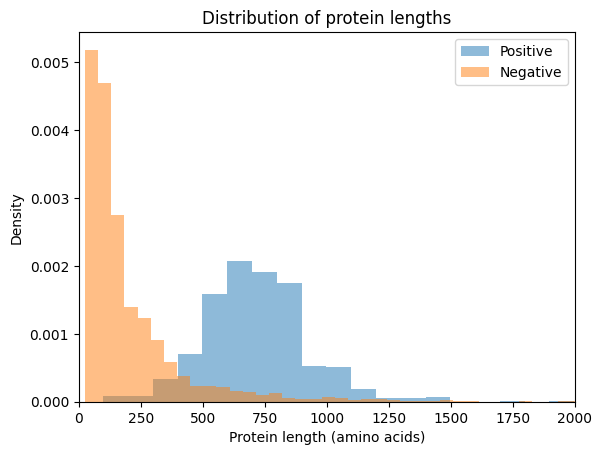

In [14]:
plt.hist(pos_lengths, bins=50, alpha=0.5, label="Positive", density=True)
plt.hist(neg_lengths, bins=50, alpha=0.5, label="Negative", density=True)

plt.xlabel("Protein length (amino acids)")
plt.ylabel("Density")
plt.legend()
plt.title("Distribution of protein lengths")
plt.xlim(0, 2000)  # corta a cauda longa
plt.show()

/var/folders/07/0gss62m90c3739dzjgm3m0pr0000gn/T/ipykernel_10938/1046675805.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([pos_lengths, neg_lengths], labels=["Positive", "Negative"])


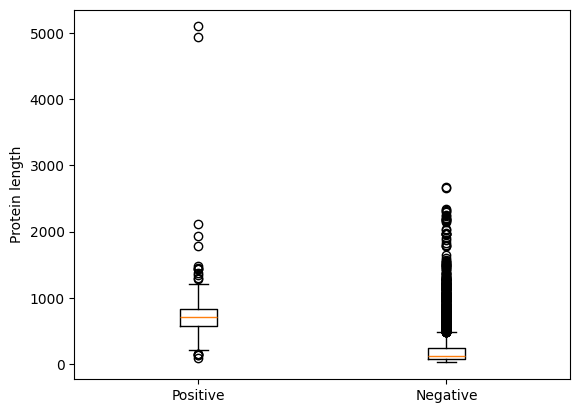

In [15]:
plt.boxplot([pos_lengths, neg_lengths], labels=["Positive", "Negative"])
plt.ylabel("Protein length")
plt.show()

Equilibrar tamanho das positivas com negativas

In [16]:
min_pos = min(pos_lengths)
max_pos = max(pos_lengths)

print(f"Positive length range: {min_pos} - {max_pos}")

Positive length range: 99 - 5096


In [17]:
neg_records = list(SeqIO.parse(neg_cdhit, "fasta"))
filtered_neg = [
    rec for rec in neg_records
    if min_pos <= len(rec.seq) <= max_pos
]

print(f"Original negatives: {len(neg_records)}")
print(f"Filtered negatives: {len(filtered_neg)}")

Original negatives: 7443
Filtered negatives: 4483


CD HIT - before vs after

In [18]:
def count_fasta(path):
    return sum(1 for _ in SeqIO.parse(path, "fasta"))

before = [
    count_fasta(positive),
    count_fasta(negative)
]

after = [
    count_fasta(pos_cdhit),
    count_fasta(neg_cdhit)
]

In [19]:
df = pd.DataFrame({
    "Dataset": ["Positive", "Negative"],
    "Before CD-HIT": before,
    "After CD-HIT": after
})

df

,Dataset,Before CD-HIT,After CD-HIT
0,Positive,1764,593
1,Negative,30000,7443


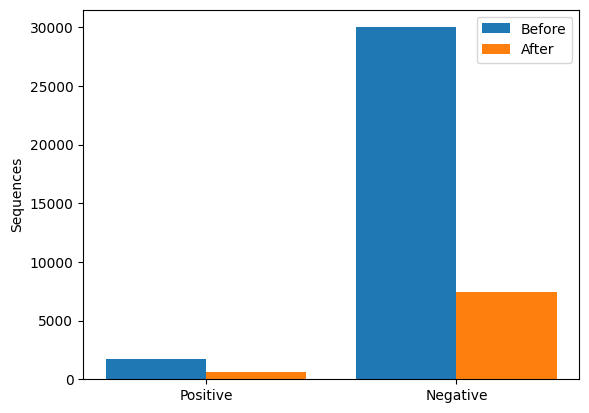

In [20]:
labels = ["Positive", "Negative"]
before 
after 

x = range(len(labels))

plt.bar(x, before, width=0.4, label="Before")
plt.bar([i+0.4 for i in x], after, width=0.4, label="After")

plt.xticks([i+0.2 for i in x], labels)
plt.ylabel("Sequences")
plt.legend()
plt.show()

1:2 positive-to-negative ratio for model development

In [ ]:
# for reproducibility
random.seed(42)

# Load all sequences from FASTA
records = filtered_neg

print(f"Total sequences: {len(records)}")

# Sample 1186 negatives
sample_size = 1186
sampled_records = random.sample(records, sample_size)

# Save sampled FASTA
SeqIO.write(sampled_records, "../data/negative/negative_sampled.fasta", "fasta")

print(f"Saved {len(sampled_records)} sampled sequences")

Total sequences: 4483
Saved 1186 sampled sequences


merge positives and negatives

In [23]:
merged_fasta = Path("../data/merged_input.fasta")
seq_counter = 1

with open(merged_fasta, "w") as out:
    # Add positives
    for rec in SeqIO.parse(pos_cdhit, "fasta"):
        new_id = f"seq{seq_counter:06d}"
        out.write(f">{new_id}|label=positive|orig_id={rec.id}\n{str(rec.seq)}\n")
        seq_counter += 1

    # Add negatives
    for rec in SeqIO.parse("../data/negative/negative_sampled.fasta", "fasta"):
        new_id = f"seq{seq_counter:06d}"
        out.write(f">{new_id}|label=negative|orig_id={rec.id}\n{str(rec.seq)}\n")
        seq_counter += 1

print(f"Merged FASTA saved to: {merged_fasta}")
print(f"Total sequences: {seq_counter - 1}")

Merged FASTA saved to: ../data/merged_input.fasta
Total sequences: 1779


In [24]:
pos_count = 0
neg_count = 0

for rec in SeqIO.parse(merged_fasta, "fasta"):
    if "label=positive" in rec.description:
        pos_count += 1
    elif "label=negative" in rec.description:
        neg_count += 1

print("Positives:", pos_count)
print("Negatives:", neg_count)

Positives: 593
Negatives: 1186


GraphPart

In [32]:
merged_fasta = Path("../data/merged_input.fasta")

seq_counter = 1
rows = []

def parse_header_info(rec):
    desc = rec.description
    orig_id = rec.id

    # remover o ID inicial da descrição, se estiver repetido
    rest = desc[len(orig_id):].strip() if desc.startswith(orig_id) else desc

    # extrair organismo entre [...]
    organism_match = re.search(r"\[(.*?)\]", rest)
    organism = organism_match.group(1) if organism_match else None

    # descrição/produto sem o organismo no fim
    product = re.sub(r"\s*\[.*?\]\s*$", "", rest).strip() if rest else None

    return orig_id, product, organism, desc

with open(merged_fasta, "w") as out:
    # positivos
    for rec in SeqIO.parse(pos_cdhit, "fasta"):
        new_id = f"seq{seq_counter:06d}"
        orig_id, product, organism, full_description = parse_header_info(rec)
        seq = str(rec.seq)

        # FASTA minimalista e seguro para GraphPart
        out.write(f">{new_id}|label=positive|orig_id={orig_id}\n{seq}\n")

        # metadata completa
        rows.append({
            "seq_id": new_id,
            "label": "positive",
            "orig_id": orig_id,
            "product": product,
            "organism": organism,
            "full_description": full_description,
            "sequence": seq
        })

        seq_counter += 1

    # negativos
    for rec in SeqIO.parse("../data/negative/negative_sampled.fasta", "fasta"):
        new_id = f"seq{seq_counter:06d}"
        orig_id, product, organism, full_description = parse_header_info(rec)
        seq = str(rec.seq)

        out.write(f">{new_id}|label=negative|orig_id={orig_id}\n{seq}\n")

        rows.append({
            "seq_id": new_id,
            "label": "negative",
            "orig_id": orig_id,
            "product": product,
            "organism": organism,
            "full_description": full_description,
            "sequence": seq
        })

        seq_counter += 1

meta_df = pd.DataFrame(rows)
meta_df

#meta_df.to_csv(metadata_csv, index=False)

,seq_id,label,orig_id,product,organism,full_description,sequence
0,seq000001,positive,DAU34648.1,MAG TPA: GDSL-like Lipase/Acylhydrolase,Caudoviricetes sp.,DAU34648.1 MAG TPA: GDSL-like Lipase/Acylhydro...,MVYQRHFWKDYDESKTETQNIEDGAVVTTEKLNEMEVGIDSKSDKT...
1,seq000002,positive,DAZ29745.1,MAG TPA: GDSL like Lipase Acylhydrolase,Caudoviricetes sp.,DAZ29745.1 MAG TPA: GDSL like Lipase Acylhydro...,MSLSDIVYNIRHAVYAKKVREAIASAIEEISKKEDKNLEIYNNMVI...
2,seq000003,positive,DAG94765.1,MAG TPA: GDSL like Lipase Acylhydrolase,Herelleviridae sp.,DAG94765.1 MAG TPA: GDSL like Lipase Acylhydro...,MGEFVGGRIVPKHCGVWSKNSKYEMLSIVYQPETGDSYISRKSVPA...
3,seq000004,positive,QNR53847.1,putative SGNH/GDSL hydrolase family protein,Pseudomonas phage phiK7A1,QNR53847.1 putative SGNH/GDSL hydrolase family...,MSCTQESPMKTRDDLIEAHNSIGFVGLLADGSLDNLILDLNEVDNT...
4,seq000005,positive,YP_009196519.1,head decoration,Cronobacter phage S13,YP_009196519.1 head decoration [Cronobacter ph...,MNKCNVFPMPWVHTSFRPLGYWVLDELESQFKKKKNFMTDYAEYKY...
...,...,...,...,...,...,...,...
1774,seq001775,negative,YP_013537806.1,structural protein,Septuagintavirus sv54,YP_013537806.1 structural protein [Septuaginta...,MAYEDKVVDVEVTLGTQPIDTVGFETPMFLAVHNNFPERLRLYGSV...
1775,seq001776,negative,YP_012319487.1,hypothetical protein,Salmonella phage F61,YP_012319487.1 hypothetical protein [Salmonell...,MLKVSEINYPITFHFTDSKGSITYNSSDSKGIWRSGVESMFGVDTF...
1776,seq001777,negative,YP_012026642.1,hypothetical protein,Escherichia phage EC100,YP_012026642.1 hypothetical protein [Escherich...,MGTNMIRVLRELIEKARKHGDTASVKHLSTILGDLQRIDKDCVSRL...
1777,seq001778,negative,YP_013605378.1,TPA: tail completion or Neck1 protein,Caudoviricetes sp. vir080,YP_013605378.1 TPA: tail completion or Neck1 p...,MKCVNMLFGMDISFNPSYYKKLGLKGKGFQQPLENTLDHGLHDAET...


In [34]:
assign_df = pd.read_csv("../graphpart_assignments.csv")

full_df = meta_df.merge(assign_df, left_on="seq_id", right_on="AC", how="left")

In [35]:
full_df = full_df.drop(columns=["AC"])

In [36]:
cluster_to_split = {
    0.0: "train",
    1.0: "test",
    2.0: "valid"
}

full_df["split"] = full_df["cluster"].map(cluster_to_split)

In [43]:
print(full_df["cluster"].value_counts())
print(full_df["cluster"].value_counts(normalize=True).sort_index())

cluster
0.0    1513
1.0     178
2.0      88
Name: count, dtype: int64
cluster
0.0    0.850478
1.0    0.100056
2.0    0.049466
Name: proportion, dtype: float64


In [37]:
print(full_df["split"].value_counts())
print(full_df["cluster"].isna().sum())

split
train    1513
test      178
valid      88
Name: count, dtype: int64
0


In [ ]:
full_df

,seq_id,label,orig_id,product,organism,full_description,sequence,priority,label-val,cluster,split
0,seq000001,positive,DAU34648.1,MAG TPA: GDSL-like Lipase/Acylhydrolase,Caudoviricetes sp.,DAU34648.1 MAG TPA: GDSL-like Lipase/Acylhydro...,MVYQRHFWKDYDESKTETQNIEDGAVVTTEKLNEMEVGIDSKSDKT...,False,0,0.0,train
1,seq000002,positive,DAZ29745.1,MAG TPA: GDSL like Lipase Acylhydrolase,Caudoviricetes sp.,DAZ29745.1 MAG TPA: GDSL like Lipase Acylhydro...,MSLSDIVYNIRHAVYAKKVREAIASAIEEISKKEDKNLEIYNNMVI...,False,0,0.0,train
2,seq000003,positive,DAG94765.1,MAG TPA: GDSL like Lipase Acylhydrolase,Herelleviridae sp.,DAG94765.1 MAG TPA: GDSL like Lipase Acylhydro...,MGEFVGGRIVPKHCGVWSKNSKYEMLSIVYQPETGDSYISRKSVPA...,False,0,0.0,train
3,seq000004,positive,QNR53847.1,putative SGNH/GDSL hydrolase family protein,Pseudomonas phage phiK7A1,QNR53847.1 putative SGNH/GDSL hydrolase family...,MSCTQESPMKTRDDLIEAHNSIGFVGLLADGSLDNLILDLNEVDNT...,False,0,1.0,test
4,seq000005,positive,YP_009196519.1,head decoration,Cronobacter phage S13,YP_009196519.1 head decoration [Cronobacter ph...,MNKCNVFPMPWVHTSFRPLGYWVLDELESQFKKKKNFMTDYAEYKY...,False,0,0.0,train
...,...,...,...,...,...,...,...,...,...,...,...
1774,seq001775,negative,YP_013537806.1,structural protein,Septuagintavirus sv54,YP_013537806.1 structural protein [Septuaginta...,MAYEDKVVDVEVTLGTQPIDTVGFETPMFLAVHNNFPERLRLYGSV...,False,1,0.0,train
1775,seq001776,negative,YP_012319487.1,hypothetical protein,Salmonella phage F61,YP_012319487.1 hypothetical protein [Salmonell...,MLKVSEINYPITFHFTDSKGSITYNSSDSKGIWRSGVESMFGVDTF...,False,1,0.0,train
1776,seq001777,negative,YP_012026642.1,hypothetical protein,Escherichia phage EC100,YP_012026642.1 hypothetical protein [Escherich...,MGTNMIRVLRELIEKARKHGDTASVKHLSTILGDLQRIDKDCVSRL...,False,1,1.0,test
1777,seq001778,negative,YP_013605378.1,TPA: tail completion or Neck1 protein,Caudoviricetes sp. vir080,YP_013605378.1 TPA: tail completion or Neck1 p...,MKCVNMLFGMDISFNPSYYKKLGLKGKGFQQPLENTLDHGLHDAET...,False,1,0.0,train


In [131]:
output_path = Path("../data/final_dataset.csv")
full_df.to_csv(output_path, index=False)
print(f"Saved final dataset to: {output_path}")

Saved final dataset to: ../data/final_dataset.csv


CSV Dominios 

In [58]:
domains_dir = Path("../data/domains_positive")
print(domains_dir.exists())
print(list(domains_dir.glob("*.fasta")))

True
[PosixPath('../data/domains_positive/domain_cl22684.fasta'), PosixPath('../data/domains_positive/domain_pfam13472.fasta'), PosixPath('../data/domains_positive/domain_pfam12708.fasta'), PosixPath('../data/domains_positive/domain_pfam07212.fasta'), PosixPath('../data/domains_positive/domain_pfam12219.fasta'), PosixPath('../data/domains_positive/all_DPO_candidates.fasta'), PosixPath('../data/domains_positive/domain_cd20481.fasta'), PosixPath('../data/domains_positive/domain_pfam12217.fasta'), PosixPath('../data/domains_positive/all_DPO_positive.fasta')]


In [59]:
fasta_files = sorted(domains_dir.glob("*.fasta"))

In [60]:
def extract_protein_ids_from_fasta(fasta_path):
    protein_ids = []

    with open(fasta_path, "r") as f:
        for line in f:
            if line.startswith(">"):
                header = line[1:].strip()
                protein_id = header.split()[0]
                protein_ids.append(protein_id)

    return protein_ids

In [ ]:
all_rows = []

for fasta_file in fasta_files:
    domain_name = fasta_file.stem.split("domain_", 1)[-1]
    protein_ids = extract_protein_ids_from_fasta(fasta_file)

    for protein_id in protein_ids:
        all_rows.append({
            "protein_id": protein_id,
            "domain_file": fasta_file.name,
            "domain_name": domain_name
        })

domains_df = pd.DataFrame(all_rows)
domains_df.head()

,protein_id,domain_file,domain_name
0,ASN73455.2,domain_cd20481.fasta,cd20481
1,YP_009610433.1,domain_cd20481.fasta,cd20481
2,APD20249.1,domain_cd20481.fasta,cd20481
3,AYP68900.1,domain_cd20481.fasta,cd20481
4,ARB06757.1,domain_cd20481.fasta,cd20481


In [66]:
print("Number of rows:", len(domains_df))
print("Unique proteins:", domains_df["protein_id"].nunique())
print("Unique domains:", domains_df["domain_name"].nunique())

Number of rows: 2041
Unique proteins: 1949
Unique domains: 7


In [67]:
domains_df["domain_name"].value_counts()

domain_name
pfam12708    890
cd20481      492
pfam13472    209
pfam12219    155
cl22684      127
pfam07212    107
pfam12217     61
Name: count, dtype: int64

In [168]:
output_csv = Path("../data/protein_domains.csv")
domains_df.to_csv(output_csv, index=False)

print("Saved to:", output_csv)

Saved to: ../data/protein_domains.csv


## Análise dos dominios

count how many domains each protein has

In [47]:
protein_domains = pd.read_csv("../data/protein_domains.csv")

In [49]:
from sklearn.calibration import check_cv


domains_per_protein = (
    protein_domains.groupby("protein_id")
    .size()
    .reset_index(name="n_domains")
)

count how many domains each protein has

In [50]:
multi_domain_proteins = domains_per_protein[domains_per_protein["n_domains"] > 1]
multi_domain_proteins.head()

,protein_id,n_domains
0,AAA32285.1,2
1,AAA88489.1,2
2,AAA98101.1,2
4,AAC37340.1,4
5,AAD33394.2,2


In [51]:
print("Proteins with more than one domain:", len(multi_domain_proteins))

Proteins with more than one domain: 1696


In [69]:
clstr_path = Path("../results/cdhit/all_DPO_positive_cdhit80.fasta.clstr")

In [ ]:
clusters = []
current_cluster = None

with open(clstr_path, "r") as f:
    for line in f:
        line = line.strip()

        if line.startswith(">Cluster"):
            current_cluster = line.replace(">", "")
            continue

        match = re.search(r">(.+?)\.\.\.", line)
        if match:
            protein_id = match.group(1)
            is_representative = line.endswith("*")

            clusters.append({
                "cluster_id": current_cluster,
                "protein_id": protein_id,
                "is_representative": is_representative
            })

cluster_df = pd.DataFrame(clusters)
cluster_df.head()

In [73]:
rep_df = (
    cluster_df[cluster_df["is_representative"]]
    [["cluster_id", "protein_id"]]
    .rename(columns={"protein_id": "representative_id"})
)

rep_df.head()

,cluster_id,representative_id
0,Cluster 0,DAY75446.1
1,Cluster 1,DAW47699.1
2,Cluster 2,QBZ72050.1
3,Cluster 3,DAL46842.1
4,Cluster 4,QJD53722.1


In [76]:
cluster_map_df = cluster_df.merge(rep_df, on="cluster_id", how="left")
cluster_map_df.head()

,cluster_id,protein_id,is_representative,representative_id
0,Cluster 0,DAY75446.1,True,DAY75446.1
1,Cluster 1,DAW47699.1,True,DAW47699.1
2,Cluster 2,QBZ72050.1,True,QBZ72050.1
3,Cluster 3,DAL46842.1,True,DAL46842.1
4,Cluster 4,QJD53722.1,True,QJD53722.1


In [ ]:
tracked_df = cluster_map_df.merge(domains_df, on="protein_id", how="left")
tracked_df.head()

,cluster_id,protein_id,is_representative,representative_id,domain_file,domain_name
0,Cluster 0,DAY75446.1,True,DAY75446.1,domain_pfam13472.fasta,pfam13472
1,Cluster 1,DAW47699.1,True,DAW47699.1,domain_pfam13472.fasta,pfam13472
2,Cluster 2,QBZ72050.1,True,QBZ72050.1,domain_pfam12708.fasta,pfam12708
3,Cluster 3,DAL46842.1,True,DAL46842.1,domain_pfam12708.fasta,pfam12708
4,Cluster 4,QJD53722.1,True,QJD53722.1,domain_pfam12708.fasta,pfam12708


In [77]:
print("Proteins in clusters:", cluster_df["protein_id"].nunique())
print("Proteins with domains:", domains_df["protein_id"].nunique())
print("Proteins after merge:", tracked_df["protein_id"].nunique())

Proteins in clusters: 1684
Proteins with domains: 1949
Proteins after merge: 1684


In [78]:
rep_domains = tracked_df[
    tracked_df["protein_id"] == tracked_df["representative_id"]
]

In [85]:
domains_per_protein = (
    tracked_df.dropna(subset=["domain_name"])
    .groupby("protein_id")["domain_name"]
    .nunique()
    .reset_index(name="n_domains")
)

multi_domain_details = (
    tracked_df.dropna(subset=["domain_name"])
    .groupby("protein_id")["domain_name"]
    .agg(lambda x: "; ".join(sorted(set(x))))
    .reset_index(name="domains")
)

multi_domain_details = multi_domain_details.merge(
    domains_per_protein,
    on="protein_id",
    how="left"
)

multi_domain_details = multi_domain_details[
    multi_domain_details["n_domains"] > 1
].sort_values("n_domains", ascending=False)

multi_domain_details.head(20)

,protein_id,domains,n_domains
3,AAC37340.1,pfam12217; pfam12219,2
10,AAZ73001.1,pfam12217; pfam12219,2
1474,YP_338127.1,pfam12217; pfam12219,2
1423,YP_009887530.1,cd20481; pfam12708,2
1402,YP_009877007.1,cd20481; pfam12708,2
1382,YP_009824943.1,pfam12217; pfam12219,2
1352,YP_009789073.1,pfam12217; pfam12219,2
1344,YP_009785006.1,cd20481; pfam12219,2
1328,YP_009322784.1,pfam12217; pfam12219,2
1304,YP_009207774.1,cd20481; pfam12219,2


In [80]:
cluster_summary = (
    tracked_df.dropna(subset=["domain_name"])
    .groupby("representative_id")
    .agg({
        "protein_id": "nunique",
        "domain_name": lambda x: ";".join(set(x))
    })
    .reset_index()
)

In [81]:
before = domains_df["domain_name"].value_counts()
after = rep_domains["domain_name"].value_counts()

In [82]:
before

domain_name
pfam12708    890
cd20481      492
pfam13472    209
pfam12219    155
cl22684      127
pfam07212    107
pfam12217     61
Name: count, dtype: int64

In [83]:
after

domain_name
pfam12708    357
cd20481      154
pfam13472     75
pfam12219     20
cl22684       15
pfam07212     11
pfam12217      6
Name: count, dtype: int64

Alignment

In [86]:
# input fasta used for GraphPart
merged_fasta = Path("../data/merged_input.fasta")

# create a dictionary: seq_id -> sequence record
record_dict = {}
for rec in SeqIO.parse(merged_fasta, "fasta"):
    seq_id = rec.id.split("|")[0]
    record_dict[seq_id] = rec

10%

In [87]:
# output FASTA files
split_fastas_10 = {
    "train": Path("../alignment/10_percent/10pct_train.fasta"),
    "test": Path("../alignment/10_percent/10pct_test.fasta"),
    "valid": Path("../alignment/10_percent/10pct_valid.fasta"),
}

for split_name, out_path in split_fastas_10.items():
    seq_ids = full_df.loc[full_df["split"] == split_name, "seq_id"].tolist()
    records = [record_dict[sid] for sid in seq_ids if sid in record_dict]
    SeqIO.write(records, out_path, "fasta")
    print(f"{split_name}: wrote {len(records)} sequences to {out_path}")

train: wrote 1513 sequences to ../alignment/10_percent/10pct_train.fasta
test: wrote 178 sequences to ../alignment/10_percent/10pct_test.fasta
valid: wrote 88 sequences to ../alignment/10_percent/10pct_valid.fasta


In [88]:
sample_sizes = {
    "train": 200,
    "test": 100,
    "valid": 80
}

sampled_fastas_10 = {
    "train": Path("../alignment/10_percent/sample/10pct_train_sample.fasta"),
    "test": Path("../alignment/10_percent/sample/10pct_test_sample.fasta"),
    "valid": Path("../alignment/10_percent/sample/10pct_valid_sample.fasta"),
}

record_dict = {}
for rec in SeqIO.parse("../data/merged_input.fasta", "fasta"):
    seq_id = rec.id.split("|")[0]
    record_dict[seq_id] = rec

for split_name, n in sample_sizes.items():
    subset = full_df[full_df["split"] == split_name].sample(
        n=min(n, (full_df["split"] == split_name).sum()),
        random_state=42
    )
    records = [record_dict[sid] for sid in subset["seq_id"] if sid in record_dict]
    SeqIO.write(records, sampled_fastas_10[split_name], "fasta")
    print(f"{split_name}: wrote {len(records)} sampled sequences to {sampled_fastas_10[split_name]}")

train: wrote 200 sampled sequences to ../alignment/10_percent/sample/10pct_train_sample.fasta
test: wrote 100 sampled sequences to ../alignment/10_percent/sample/10pct_test_sample.fasta
valid: wrote 80 sampled sequences to ../alignment/10_percent/sample/10pct_valid_sample.fasta


In [89]:
def parse_needle_file(filepath):
    filepath = Path(filepath)

    identities = []
    seq1_list = []
    seq2_list = []

    seq1 = None
    seq2 = None

    with open(filepath) as f:
        for line in f:
            line = line.strip()

            if line.startswith("# 1:"):
                seq1 = line.replace("# 1:", "").strip()
            elif line.startswith("# 2:"):
                seq2 = line.replace("# 2:", "").strip()
            elif line.startswith("# Identity:"):
                m = re.search(r"\(([\d.]+)%\)", line)
                if m:
                    identity = float(m.group(1))
                    seq1_list.append(seq1)
                    seq2_list.append(seq2)
                    identities.append(identity)

    return pd.DataFrame({
        "seq1": seq1_list,
        "seq2": seq2_list,
        "identity_percent": identities
    })


In [103]:
train_test_10pct_sample_df = parse_needle_file("../alignment/10_percent/sample/10pct_train_vs_test_sample.needle")

print(train_test_10pct_sample_df.head())

                     seq1                seq2  identity_percent
0      orig_id=DAK42187.1  orig_id=APD21163.1              18.3
1  orig_id=YP_011968030.1  orig_id=APD21163.1              10.6
2      orig_id=AWY02949.1  orig_id=APD21163.1              16.8
3      orig_id=AUR97459.1  orig_id=APD21163.1              15.0
4  orig_id=YP_013608156.1  orig_id=APD21163.1              11.8


In [104]:
def summarize_identities(df, name):
    print(f"\n{name}")
    print(df["identity_percent"].describe())
    print("Maximum identity:", df["identity_percent"].max())
    print("Minimum identity:", df["identity_percent"].min())

In [105]:
summarize_identities(train_test_10pct_sample_df, "Train vs Test (10%)")


Train vs Test (10%)
count    5527.000000
mean       13.603401
std         2.715675
min        10.000000
25%        11.400000
50%        13.200000
75%        15.400000
max        49.200000
Name: identity_percent, dtype: float64
Maximum identity: 49.2
Minimum identity: 10.0


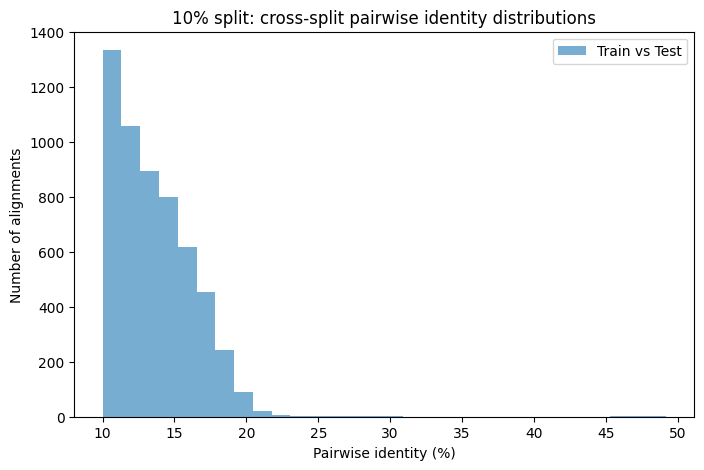

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(train_test_10pct_sample_df["identity_percent"], bins=30, alpha=0.6, label="Train vs Test")
plt.xlabel("Pairwise identity (%)")
plt.ylabel("Number of alignments")
plt.title("10% split: cross-split pairwise identity distributions")
plt.legend()
plt.show()

In [ ]:
print(train_test_10pct_sample_df["identity_percent"].max())

49.2


15%

In [96]:
split_fastas_15 = {
    "train": Path("../alignment/15_percent/15pct_train.fasta"),
    "test": Path("../alignment/15_percent/15pct_test.fasta"),
    "valid": Path("../alignment/15_percent/15pct_valid.fasta"),
}

for split_name, out_path in split_fastas_15.items():
    seq_ids = full_df.loc[full_df["split"] == split_name, "seq_id"].tolist()
    records = [record_dict[sid] for sid in seq_ids if sid in record_dict]
    SeqIO.write(records, out_path, "fasta")
    print(f"{split_name}: wrote {len(records)} sequences to {out_path}")

train: wrote 1513 sequences to ../alignment/15_percent/15pct_train.fasta
test: wrote 178 sequences to ../alignment/15_percent/15pct_test.fasta
valid: wrote 88 sequences to ../alignment/15_percent/15pct_valid.fasta


In [97]:
sampled_fastas_15 = {
    "train": Path("../alignment/15_percent/sample/15pct_train_sample.fasta"),
    "test": Path("../alignment/15_percent/sample/15pct_test_sample.fasta"),
    "valid": Path("../alignment/15_percent/sample/15pct_valid_sample.fasta"),
}

for split_name, n in sample_sizes.items():
    subset = full_df[full_df["split"] == split_name].sample(
        n=min(n, (full_df["split"] == split_name).sum()),
        random_state=42
    )
    records = [record_dict[sid] for sid in subset["seq_id"] if sid in record_dict]
    SeqIO.write(records, sampled_fastas_15[split_name], "fasta")
    print(f"{split_name}: wrote {len(records)} sampled sequences to {sampled_fastas_15[split_name]}")

train: wrote 200 sampled sequences to ../alignment/15_percent/sample/15pct_train_sample.fasta
test: wrote 100 sampled sequences to ../alignment/15_percent/sample/15pct_test_sample.fasta
valid: wrote 80 sampled sequences to ../alignment/15_percent/sample/15pct_valid_sample.fasta


In [114]:
train_test_15pct_sample_df = parse_needle_file("../alignment/15_percent/sample/15pct_train_vs_test_sample.needle")

print(train_test_15pct_sample_df.head())

                     seq1                    seq2  identity_percent
0  orig_id=YP_012040250.1  orig_id=YP_013607451.1              13.4
1  orig_id=YP_012488375.1  orig_id=YP_013607451.1              10.7
2  orig_id=YP_011540332.1  orig_id=YP_013607451.1              14.5
3  orig_id=YP_013607542.1  orig_id=YP_013607451.1              12.4
4  orig_id=YP_012892870.1  orig_id=YP_013607451.1              13.1


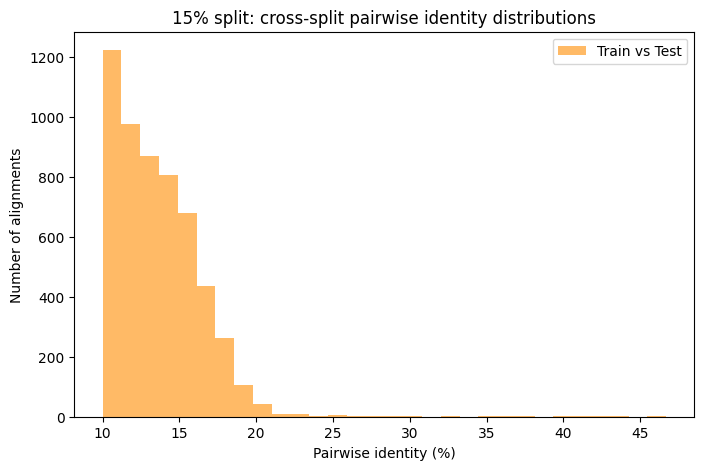

In [119]:
plt.figure(figsize=(8, 5))
plt.hist(train_test_15pct_sample_df["identity_percent"], bins=30, alpha=0.6, label="Train vs Test", color='darkorange')
plt.xlabel("Pairwise identity (%)")
plt.ylabel("Number of alignments")
plt.title("15% split: cross-split pairwise identity distributions")
plt.legend()
plt.show()

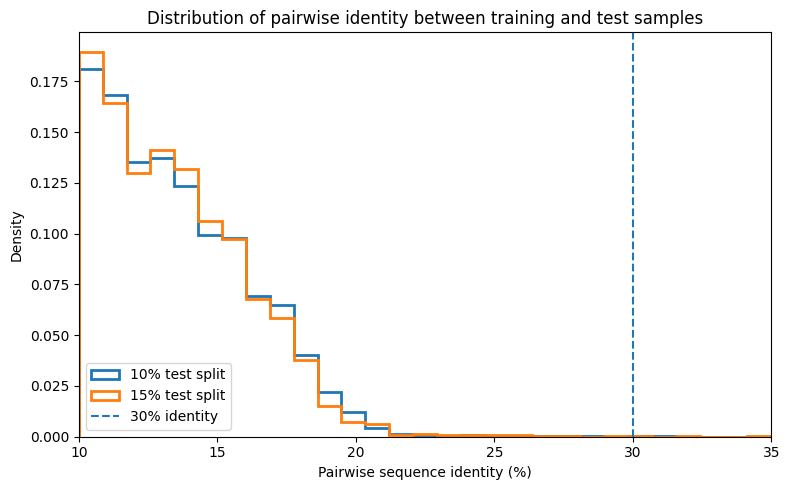

In [120]:
plt.figure(figsize=(8, 5))

bins = np.linspace(10, 35, 30)

plt.hist(
    train_test_10pct_sample_df["identity_percent"],
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="10% test split"
)

plt.hist(
    train_test_15pct_sample_df["identity_percent"],
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="15% test split"
)

# 30% identity threshold
plt.axvline(30, linestyle="--", label="30% identity")

plt.xlabel("Pairwise sequence identity (%)")
plt.ylabel("Density")
plt.title("Distribution of pairwise identity between training and test samples")

plt.legend()
plt.xlim(10, 35)

plt.tight_layout()
plt.show()

In [100]:
train_test_15pct_df = parse_needle_file("../alignment/15pct_train_vs_test.needle")
train_valid_15pct_df = parse_needle_file("../alignment/15pct_train_vs_valid.needle")

print(train_test_15pct_df.head())
print(train_valid_15pct_df.head())

                     seq1                seq2  identity_percent
0      orig_id=DAZ29745.1  orig_id=QNR53847.1              13.5
1      orig_id=DAE34131.1  orig_id=QNR53847.1              14.1
2      orig_id=QHB37258.1  orig_id=QNR53847.1              12.8
3  orig_id=YP_009598405.1  orig_id=QNR53847.1              11.4
4      orig_id=AYR03494.1  orig_id=QNR53847.1              11.7
                     seq1                seq2  identity_percent
0      orig_id=DAU34648.1  orig_id=DAI47778.1              17.3
1      orig_id=DAZ29745.1  orig_id=DAI47778.1              22.6
2      orig_id=DAG94765.1  orig_id=DAI47778.1              16.3
3  orig_id=YP_009196519.1  orig_id=DAI47778.1              15.0
4      orig_id=QEG13048.1  orig_id=DAI47778.1              15.3


In [106]:
summarize_identities(train_test_15pct_df, "Train vs Test (15%)")
summarize_identities(train_valid_15pct_df, "Train vs Validation (15%)")


Train vs Test (15%)
count    104069.000000
mean         13.572808
std           2.821834
min          10.000000
25%          11.400000
50%          13.100000
75%          15.200000
max          59.100000
Name: identity_percent, dtype: float64
Maximum identity: 59.1
Minimum identity: 10.0

Train vs Validation (15%)
count    33572.000000
mean        13.595779
std          2.737662
min         10.000000
25%         11.400000
50%         13.200000
75%         15.300000
max         54.500000
Name: identity_percent, dtype: float64
Maximum identity: 54.5
Minimum identity: 10.0


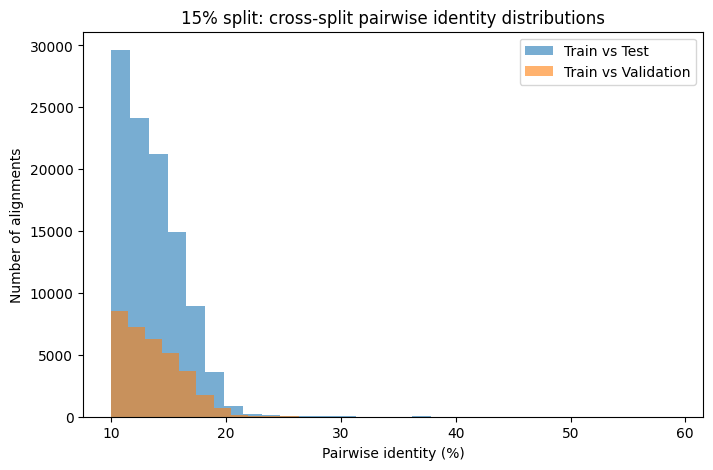

In [101]:
plt.figure(figsize=(8, 5))
plt.hist(train_test_15pct_df["identity_percent"], bins=30, alpha=0.6, label="Train vs Test")
plt.hist(train_valid_15pct_df["identity_percent"], bins=30, alpha=0.6, label="Train vs Validation")
plt.xlabel("Pairwise identity (%)")
plt.ylabel("Number of alignments")
plt.title("15% split: cross-split pairwise identity distributions")
plt.legend()
plt.show()

Deeplearning

In [6]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from embedding.embedding_extractor import ProteinEmbedder

In [7]:
import importlib
import embedding.embedding_extractor as ee

importlib.reload(ee)
ProteinEmbedder = ee.ProteinEmbedder

ESM

In [138]:
esm_embedder = ProteinEmbedder(
    model_name="facebook/esm2_t12_35M_UR50D",
    model_type="esm"
)

Loading weights:   0%|          | 0/209 [00:00<?, ?it/s]

EsmModel LOAD REPORT from: facebook/esm2_t12_35M_UR50D
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
esm.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
pooler.dense.bias           | MISSING    | 
pooler.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [13]:
df = pd.read_csv("../data/final_dataset.csv")

In [ ]:
esm_embeddings = esm_embedder.embed_sequences(
    df["sequence"].tolist(),
    max_length=1024
)
np.save("../results/embeddings/esm_embeddings.npy", esm_embeddings)

In [142]:
print(esm_embeddings.shape)

(1779, 480)


ProtT5

In [8]:
prott5_embedder = ProteinEmbedder(
    model_name="Rostlab/prot_t5_xl_uniref50",
    model_type="prott5"
)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
T5EncoderModel LOAD REPORT from: Rostlab/prot_t5_xl_uniref50
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ProtBert

In [19]:
protbert_embedder = ProteinEmbedder(
    model_name="Rostlab/prot_bert",
    model_type="bert"
)

ValueError: model_type must be one of: 'protbert', 'prott5', or 'esm'